In [ ]:
!pip install -q tensorflow scikit-learn pandas matplotlib seaborn

In [ ]:

import tensorflow as tf
import numpy as np
import time

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Configuration
vocab_size = 10000
max_length = 200

# Load IMDB dataset
(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))
print("First review token IDs:", x_train[0][:20])
print("First review label:", y_train[0])


Training samples: 25000
Testing samples: 25000
First review token IDs: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First review label: 1


In [ ]:

# Make all reviews the same length
x_train_pad = pad_sequences(
    x_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

x_test_pad = pad_sequences(
    x_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training data shape:", x_train_pad.shape)
print("Testing data shape:", x_test_pad.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)


Training data shape: (25000, 200)
Testing data shape: (25000, 200)
Training labels shape: (25000,)
Testing labels shape: (25000,)


In [ ]:

import tensorflow as tf
import time

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D
from tensorflow.keras.layers import Dense, Dropout

# CNN model
cnn_model = Sequential([
    Embedding(input_dim=10000, output_dim=64, input_length=200),
    Conv1D(filters=128, kernel_size=5, activation="relu"),
    GlobalMaxPooling1D(),
    Dense(64, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

# Compile model
cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:

start_time = time.time()

cnn_history = cnn_model.fit(
    x_train_pad,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

cnn_training_time = time.time() - start_time

print("CNN Training Time:", round(cnn_training_time, 2), "seconds")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.7203 - loss: 0.5276 - val_accuracy: 0.8458 - val_loss: 0.3501
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8827 - loss: 0.2879 - val_accuracy: 0.8770 - val_loss: 0.3068
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9511 - loss: 0.1445 - val_accuracy: 0.8728 - val_loss: 0.3660
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9832 - loss: 0.0594 - val_accuracy: 0.8752 - val_loss: 0.4186
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9901 - loss: 0.0328 - val_accuracy: 0.8708 - val_loss: 0.4865
CNN Training Time: 18.33 seconds


In [ ]:

# Evaluate CNN on unseen test data

test_loss, test_accuracy = cnn_model.evaluate(
    x_test_pad,
    y_test,
    verbose=1
)

print("CNN Test Loss:", round(test_loss, 4))
print("CNN Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("CNN Training Time:", round(cnn_training_time, 2), "seconds")


782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8502 - loss: 0.5497
CNN Test Loss: 0.5497
CNN Test Accuracy: 85.02 %
CNN Training Time: 18.33 seconds


In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
import time

# Build LSTM model
lstm_model = Sequential([
    Embedding(input_dim=10000, output_dim=64),
    LSTM(64),
    Dropout(0.5),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Compile model
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:

start_time = time.time()

lstm_history = lstm_model.fit(
    x_train_pad,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

lstm_training_time = time.time() - start_time

print("LSTM Training Time:", round(lstm_training_time, 2), "seconds")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5076 - loss: 0.6934 - val_accuracy: 0.5046 - val_loss: 0.6926
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5713 - loss: 0.6625 - val_accuracy: 0.6118 - val_loss: 0.6359
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6482 - loss: 0.5884 - val_accuracy: 0.8126 - val_loss: 0.5100
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7596 - loss: 0.5240 - val_accuracy: 0.7188 - val_loss: 0.6455
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.7311 - loss: 0.5538 - val_accuracy: 0.6322 - val_loss: 0.7591
LSTM Training Time: 25.86 seconds


In [ ]:

# Evaluate LSTM on unseen test data

lstm_test_loss, lstm_test_accuracy = lstm_model.evaluate(
    x_test_pad,
    y_test,
    verbose=1
)

print("LSTM Test Loss:", round(lstm_test_loss, 4))
print("LSTM Test Accuracy:", round(lstm_test_accuracy * 100, 2), "%")
print("LSTM Training Time:", round(lstm_training_time, 2), "seconds")

782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6257 - loss: 0.7631
LSTM Test Loss: 0.7631
LSTM Test Accuracy: 62.57 %
LSTM Training Time: 25.86 seconds


In [ ]:

import numpy as np
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, classification_report

# Predict probabilities
cnn_prob = cnn_model.predict(x_test_pad, verbose=0)
lstm_prob = lstm_model.predict(x_test_pad, verbose=0)

# Convert probabilities into class labels
cnn_pred = (cnn_prob >= 0.5).astype(int).ravel()
lstm_pred = (lstm_prob >= 0.5).astype(int).ravel()

# Calculate and display metrics
for name, predictions in [
    ("CNN", cnn_pred),
    ("LSTM", lstm_pred)
]:
    print(f"\n===== {name} Results =====")
    print("Accuracy :", round(accuracy_score(y_test, predictions), 4))
    print("Precision:", round(precision_score(y_test, predictions, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_test, predictions, zero_division=0), 4))
    print("F1-score :", round(f1_score(y_test, predictions, zero_division=0), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions,
        target_names=["Negative", "Positive"],
        zero_division=0
    ))



===== CNN Results =====
Accuracy : 0.8502
Precision: 0.8848
Recall   : 0.8053
F1-score : 0.8432

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.90      0.86     12500
    Positive       0.88      0.81      0.84     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000


===== LSTM Results =====
Accuracy : 0.6257
Precision: 0.575
Recall   : 0.9634
F1-score : 0.7202

Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.29      0.43     12500
    Positive       0.58      0.96      0.72     12500

    accuracy                           0.63     25000
   macro avg       0.73      0.63      0.58     25000
weighted avg       0.73      0.63      0.58     25000



In [ ]:

import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Training Time (seconds)"
    ],
    "CNN": [
        accuracy_score(y_test, cnn_pred),
        precision_score(y_test, cnn_pred, zero_division=0),
        recall_score(y_test, cnn_pred, zero_division=0),
        f1_score(y_test, cnn_pred, zero_division=0),
        cnn_training_time
    ],
    "LSTM": [
        accuracy_score(y_test, lstm_pred),
        precision_score(y_test, lstm_pred, zero_division=0),
        recall_score(y_test, lstm_pred, zero_division=0),
        f1_score(y_test, lstm_pred, zero_division=0),
        lstm_training_time
    ]
})

print(comparison.round(4).to_string(index=False))


                 Metric     CNN    LSTM
          Test Accuracy  0.8502  0.6257
              Precision  0.8848  0.5750
                 Recall  0.8053  0.9634
               F1-score  0.8432  0.7202
Training Time (seconds) 18.3299 25.8622


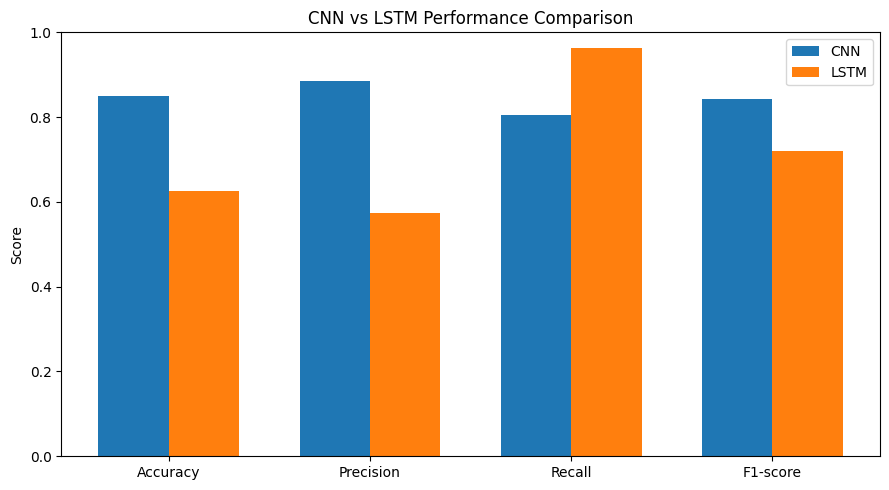

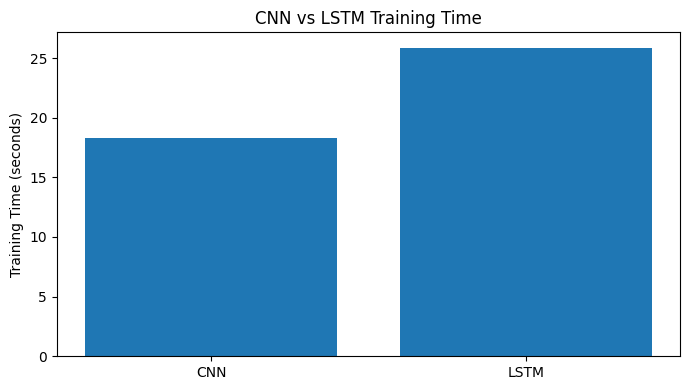

In [ ]:

import matplotlib.pyplot as plt

# Model performance metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

cnn_scores = [
    accuracy_score(y_test, cnn_pred),
    precision_score(y_test, cnn_pred, zero_division=0),
    recall_score(y_test, cnn_pred, zero_division=0),
    f1_score(y_test, cnn_pred, zero_division=0)
]

lstm_scores = [
    accuracy_score(y_test, lstm_pred),
    precision_score(y_test, lstm_pred, zero_division=0),
    recall_score(y_test, lstm_pred, zero_division=0),
    f1_score(y_test, lstm_pred, zero_division=0)
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, cnn_scores, width, label="CNN")
plt.bar(x + width/2, lstm_scores, width, label="LSTM")
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("CNN vs LSTM Performance Comparison")
plt.legend()
plt.tight_layout()
plt.show()

# Training time comparison
plt.figure(figsize=(7, 4))
plt.bar(
    ["CNN", "LSTM"],
    [cnn_training_time, lstm_training_time]
)
plt.ylabel("Training Time (seconds)")
plt.title("CNN vs LSTM Training Time")
plt.tight_layout()
plt.show()


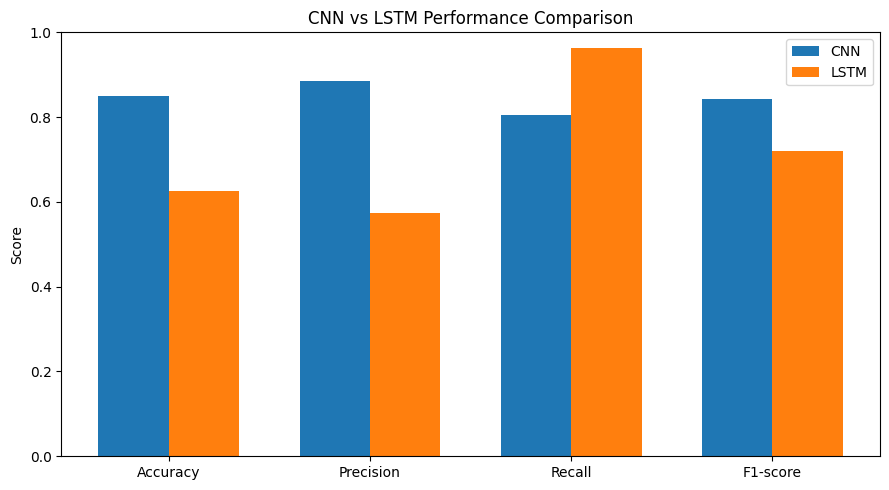

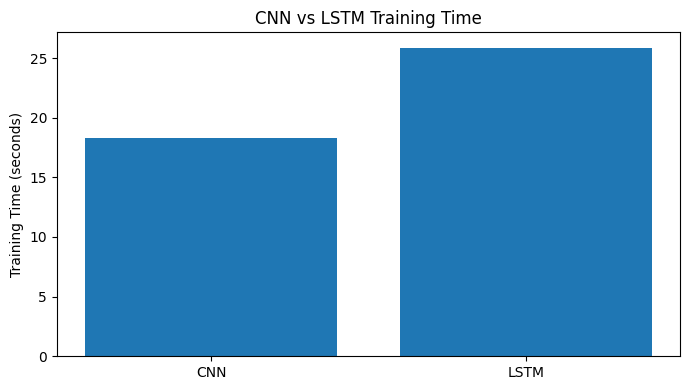

All project results saved successfully!
Folder: /content/CNN_LSTM_Project

Saved files:
cnn_model.keras
lstm_model.keras
model_comparison.csv
performance_comparison.png
results_summary.txt
training_time_comparison.png


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Create a folder for project results
save_dir = "/content/CNN_LSTM_Project"
os.makedirs(save_dir, exist_ok=True)

# 1. Save comparison table
comparison.to_csv(
    os.path.join(save_dir, "model_comparison.csv"),
    index=False
)

# 2. Save performance graph
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

cnn_scores = [
    accuracy_score(y_test, cnn_pred),
    precision_score(y_test, cnn_pred, zero_division=0),
    recall_score(y_test, cnn_pred, zero_division=0),
    f1_score(y_test, cnn_pred, zero_division=0)
]

lstm_scores = [
    accuracy_score(y_test, lstm_pred),
    precision_score(y_test, lstm_pred, zero_division=0),
    recall_score(y_test, lstm_pred, zero_division=0),
    f1_score(y_test, lstm_pred, zero_division=0)
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, cnn_scores, width, label="CNN")
plt.bar(x + width/2, lstm_scores, width, label="LSTM")
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("CNN vs LSTM Performance Comparison")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(save_dir, "performance_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 3. Save training time graph
plt.figure(figsize=(7, 4))
plt.bar(
    ["CNN", "LSTM"],
    [cnn_training_time, lstm_training_time]
)
plt.ylabel("Training Time (seconds)")
plt.title("CNN vs LSTM Training Time")
plt.tight_layout()
plt.savefig(
    os.path.join(save_dir, "training_time_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 4. Save trained models
cnn_model.save(os.path.join(save_dir, "cnn_model.keras"))
lstm_model.save(os.path.join(save_dir, "lstm_model.keras"))

# 5. Save results summary
with open(os.path.join(save_dir, "results_summary.txt"), "w") as f:
    f.write("CNN vs LSTM Text Classification Results\n\n")
    f.write(comparison.round(4).to_string(index=False))
    f.write("\n\nCNN training time: {:.2f} seconds".format(cnn_training_time))
    f.write("\nLSTM training time: {:.2f} seconds".format(lstm_training_time))

print("All project results saved successfully!")
print("Folder:", save_dir)
print("\nSaved files:")
for filename in sorted(os.listdir(save_dir)):
    print(filename)


In [ ]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/CNN_LSTM_Project",
    "zip",
    "/content/CNN_LSTM_Project"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>